from google.colab import files

uploaded = files.upload()

In [1]:
import pandas as pd

df = pd.read_csv("lifecyclesavings.csv")

df.head()

,Contry,sr,pop15,pop75,dpi,ddpi
0,Australia,11.43,29.35,2.87,2329.68,2.87
1,Austria,12.07,23.32,4.41,1507.99,3.93
2,Belgium,13.17,23.80,4.43,2108.47,3.82
3,Bolivia,5.75,41.89,1.67,189.13,0.22
4,Brazil,12.88,42.19,0.83,728.47,4.56


In [2]:
df.shape

(50, 6)

In [3]:
df.isnull().sum()

,0
Contry,0
sr,0
pop15,0
pop75,0
dpi,0
ddpi,0


In [4]:
df.mean(numeric_only=True)

,0
sr,9.6710
pop15,35.0896
pop75,2.2930
dpi,1106.7584
ddpi,3.7576




I loaded the life-cycle savings dataset and inspected it before using AI.

- **Dataset shape:** 50 rows and 6 columns.
- **Missing values:** All six columns have 0 missing values.
- **Mean of `sr`:** 9.6710
- **Mean of `pop15`:** 35.0896
- **Mean of `pop75`:** 2.2930
- **Mean of `dpi`:** 1106.7584
- **Mean of `ddpi`:** 3.7576

The baseline helps me understand the overall dataset before clustering the countries into groups. I will use these overall means to verify whether the clusters have different characteristics.

I completed the dataset baseline before asking AI for help. I am now using AI to learn clustering, a technique I have not formally studied in this course.

I am a beginner in data science working on a life-cycle savings dataset with one row per country. My dataset has 50 rows and these columns: Country, sr, pop15, pop75, dpi, and ddpi. I calculated the overall numeric column means and checked that there are no missing values.

Please teach me how to use clustering to group countries with similar savings behavior. Recommend an appropriate beginner-friendly clustering method. Explain why scaling may be needed, provide Python code that I can run in Google Colab, and create a clearly labeled chart that helps me interpret the clusters. Explain each step in simple language. Do not invent results. Tell me how I can verify the results independently and identify any limitations of the method.

I will teach you how to apply K-Means Clustering (the most beginner-friendly and widely used clustering method) to your dataset.

Why do we need Scaling?
In your dataset, the columns have completely different ranges:

dpi (Disposable Income) has a mean of over 1106.75 (with values potentially reaching several thousands).
ddpi (growth rate of dpi) and pop75 have means of 3.75 and 2.29 respectively.
Because K-Means uses straight-line distance (Euclidean distance) to group data, features with large numbers (like dpi) will completely dominate the distance calculations, making features with small numbers (like pop75) irrelevant. Scaling converts all columns so they have a mean of 0 and variance of 1, giving every feature equal weight in finding similar countries.

I will insert cells containing the step-by-step code and clear explanations right after your prompt cell.

In [5]:
features = df[["sr", "pop15", "pop75", "dpi", "ddpi"]]

features.head()

,sr,pop15,pop75,dpi,ddpi
0,11.43,29.35,2.87,2329.68,2.87
1,12.07,23.32,4.41,1507.99,3.93
2,13.17,23.80,4.43,2108.47,3.82
3,5.75,41.89,1.67,189.13,0.22
4,12.88,42.19,0.83,728.47,4.56


In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaled_features = scaler.fit_transform(features)

scaled_features[:5]

array([[ 0.39658414, -0.63352758,  0.4515579 ,  1.24672132, -0.31242224],
       [ 0.54087854, -1.29910903,  1.65675574,  0.40904011,  0.06068228],
       [ 0.78888455, -1.24612742,  1.67240766,  1.02120627,  0.02196389],
       [-0.88402867,  0.75061693, -0.48755731, -0.9354867 , -1.24518353],
       [ 0.72350114,  0.78373044, -1.14493796, -0.38565041,  0.28243308]])

In [7]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

clusters = kmeans.fit_predict(scaled_features)

clusters

array([2, 2, 2, 0, 1, 2, 0, 1, 0, 0, 2, 0, 2, 2, 2, 2, 0, 0, 2, 0, 2, 2,
       1, 0, 2, 1, 2, 2, 2, 0, 0, 0, 0, 0, 1, 2, 1, 2, 2, 2, 0, 0, 2, 2,
       0, 1, 1, 2, 1, 0], dtype=int32)

In [8]:
df["Cluster"] = clusters

df[["Contry", "Cluster"]].head(10)

,Contry,Cluster
0,Australia,2
1,Austria,2
2,Belgium,2
3,Bolivia,0
4,Brazil,1
5,Canada,2
6,Chile,0
7,China,1
8,Colombia,0
9,Costa Rica,0


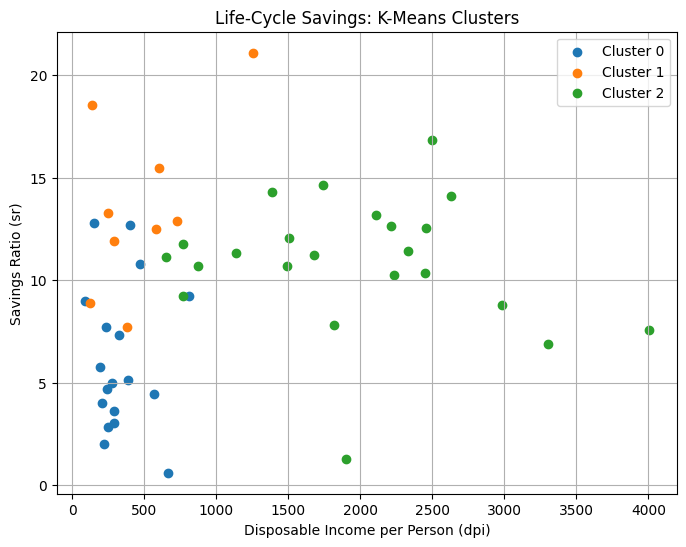

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

for cluster_id in sorted(df["Cluster"].unique()):
    group = df[df["Cluster"] == cluster_id]
    plt.scatter(group["dpi"], group["sr"], label=f"Cluster {cluster_id}")

plt.xlabel("Disposable Income per Person (dpi)")
plt.ylabel("Savings Ratio (sr)")
plt.title("Life-Cycle Savings: K-Means Clusters")
plt.legend()
plt.grid(True)
plt.show()

In [10]:
df["Cluster"].value_counts().sort_index()

,count
Cluster,
0,18
1,9
2,23


In [11]:
cluster_0 = df[df["Cluster"] == 0]

cluster_0[["sr", "pop15", "pop75", "dpi", "ddpi"]].mean()

,0
sr,6.138889
pop15,44.556111
pop75,1.079444
dpi,337.153333
ddpi,2.359444


I selected Cluster 0 and independently calculated its column means using pandas.

Interpretation

Cluster 0: Countries in Cluster 0 have a lower savings ratio than the average. They also have more young people under age 15 and lower disposable income per person. This shows that these countries have some different economic and population characteristics. I would look at the other clusters before making a final conclusion.

Caution About AI

AI can help me write code and explain things I am still learning. However, I should not trust the results without checking them. I need to run the code, check the numbers, and make sure I understand what they mean. Clustering results can also change depending on how many groups I choose and how I prepare the data.